Student Dataset:


,Study_Hours,Attendance,Result
0,1,50,Fail
1,2,60,Fail
2,4,65,Fail
3,5,70,Fail
4,1,80,Pass
5,2,85,Pass
6,4,90,Pass
7,5,95,Pass


Training Records: 6
Testing Records: 2
Decision Tree Model Trained Successfully!


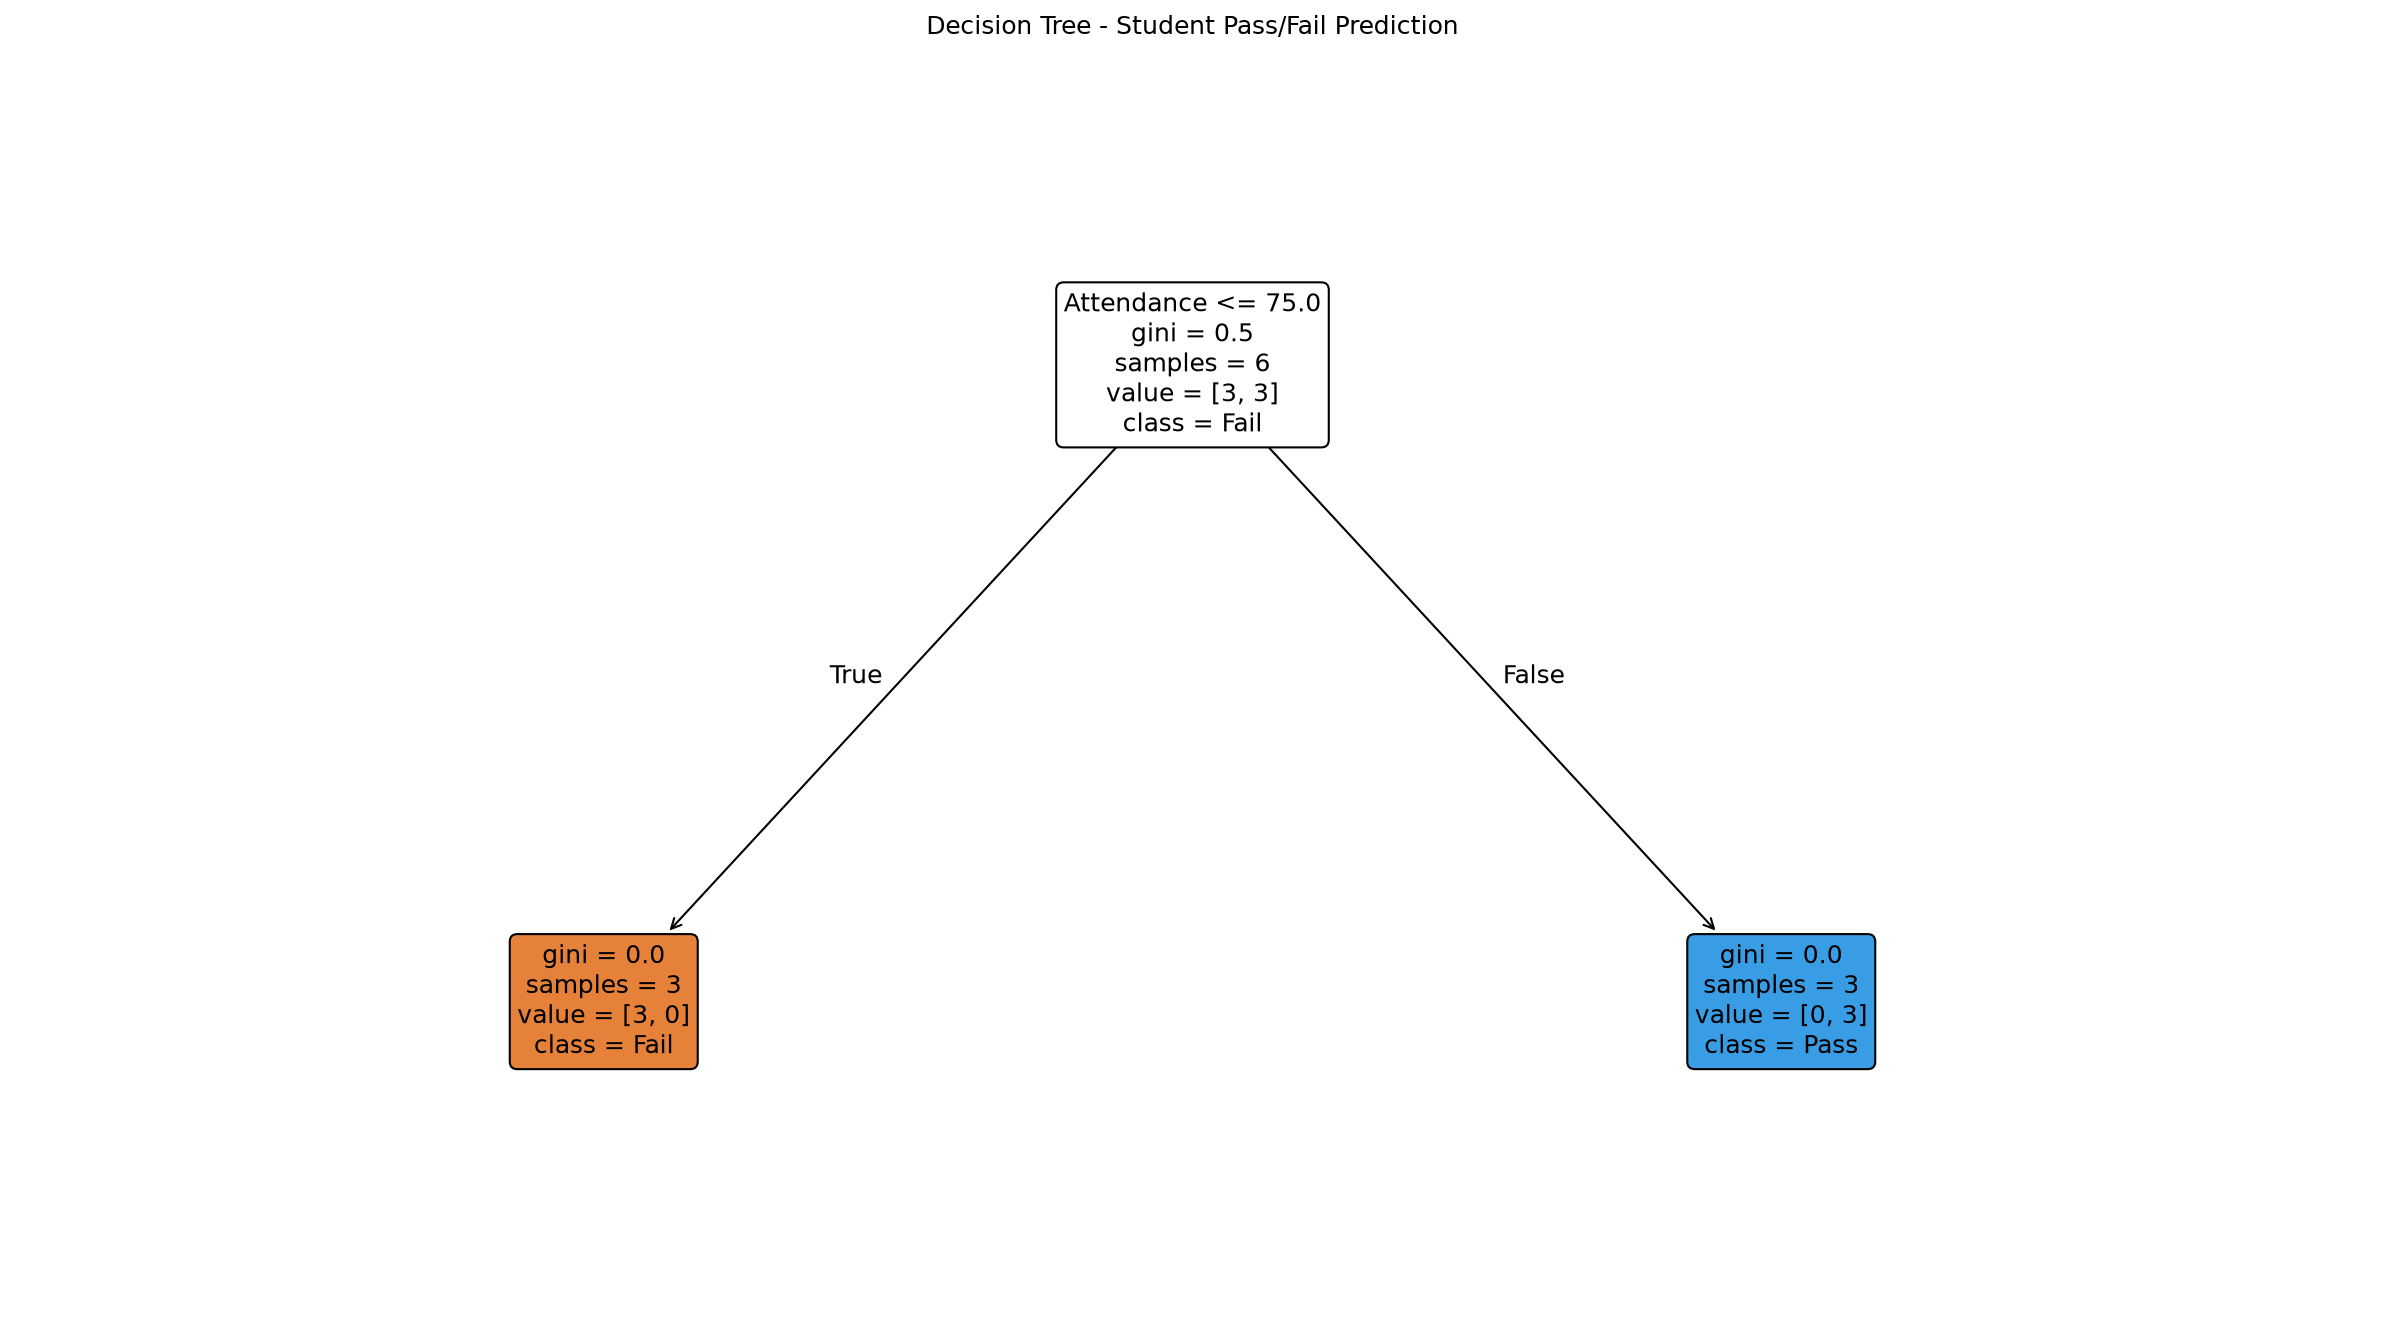

Actual Results:
['Fail' 'Pass']

Predicted Results:
['Fail' 'Pass']
Model Accuracy: 100.0 %
Confusion Matrix:
[[1 0]
 [0 1]]


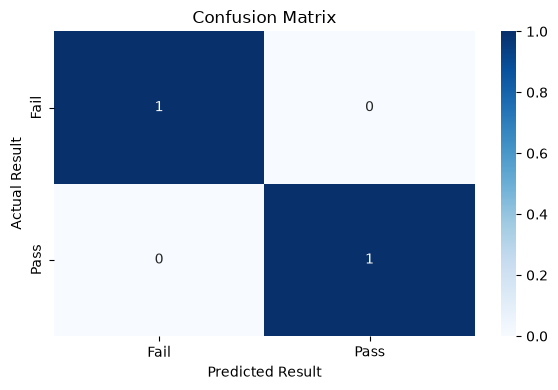

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

New Student Details:


,Study_Hours,Attendance
0,4,85


Predicted Student Result: Pass


In [1]:
%matplotlib inline


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

data = {
    "Study_Hours": [1, 2, 4, 5, 1, 2, 4, 5],
    "Attendance": [50, 60, 65, 70, 80, 85, 90, 95],
    "Result": [
        "Fail", "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass"
    ]
}

df = pd.DataFrame(data)

print("Student Dataset:")
display(df)

X = df[["Study_Hours", "Attendance"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

plt.figure(figsize=(16, 9), dpi=150)

plot_tree(
    model,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=12
)

plt.title("Decision Tree - Student Pass/Fail Prediction")
plt.tight_layout()
plt.show()

y_pred = model.predict(X_test)

print("Actual Results:")
print(y_test.values)

print("\nPredicted Results:")
print(y_pred)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        zero_division=0
    )
)

new_student = pd.DataFrame({
    "Study_Hours": [4],
    "Attendance": [85]
})

prediction = model.predict(new_student)

print("New Student Details:")
display(new_student)

print("Predicted Student Result:", prediction[0])

Confusion Matrix:
[[1 0]
 [0 1]]


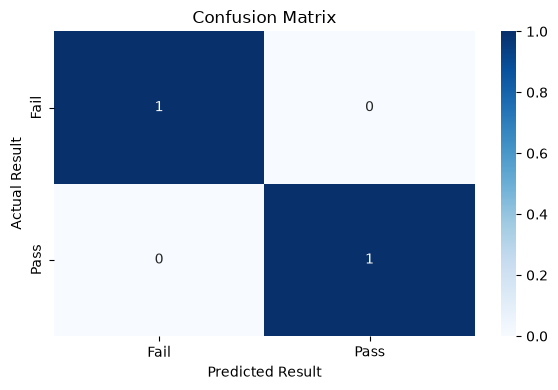

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail", "Pass"]
)

print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()